## Logistic Regression

In [2]:
import numpy as np
import pandas as pd

# Set seed for reproducibility
np.random.seed(42)
n_samples = 150

# 1. Feature Generation
time_spent_on_site = np.random.normal(loc=12, scale=5, size=n_samples)  # in minutes
time_spent_on_site = np.clip(time_spent_on_site, 1, 45).round(2)

pages_visited = np.random.poisson(lam=4, size=n_samples) + 1  # minimum 1 page

previous_purchases = np.random.choice(
    [0, 1, 2, 3, 4, 5], 
    size=n_samples, 
    p=[0.45, 0.25, 0.15, 0.08, 0.04, 0.03]
)

# 2. Linear Combination (Log-Odds)
# B0 (intercept) + B1*time + B2*pages + B3*purchases
log_odds = (
    -3.5 
    + 0.12 * time_spent_on_site 
    + 0.35 * pages_visited 
    + 0.60 * previous_purchases
)

# 3. Probability via Sigmoid Function: 1 / (1 + e^(-log_odds))
probabilities = 1 / (1 + np.exp(-log_odds))

# 4. Generate Binary Target Variable
will_purchase = np.random.binomial(1, probabilities)

# 5. Assemble DataFrame
df = pd.DataFrame({
    'time_spent_on_site': time_spent_on_site,
    'pages_visited': pages_visited,
    'previous_purchases': previous_purchases,
    'will_purchase': will_purchase
})

# Display summary
print(df.head())
print("\nTarget Class Distribution:")
print(df['will_purchase'].value_counts(normalize=True))

   time_spent_on_site  pages_visited  previous_purchases  will_purchase
0               14.48              5                   0              0
1               11.31              3                   1              1
2               15.24              3                   1              0
3               19.62              5                   0              0
4               10.83              7                   0              0

Target Class Distribution:
will_purchase
1    0.506667
0    0.493333
Name: proportion, dtype: float64


In [3]:
time_spent_on_site = np.random.normal(loc=12, scale=5, size=n_samples)  # in minutes
time_spent_on_site = np.clip(time_spent_on_site, 1, 45).round(2)

pages_visited = np.random.poisson(lam=4, size=n_samples) + 1  # minimum 1 page

previous_purchases = np.random.choice(
    [0, 1, 2, 3, 4, 5], 
    size=n_samples, 
    p=[0.45, 0.25, 0.15, 0.08, 0.04, 0.03]
)

# 2. Linear Combination (Log-Odds)
# B0 (intercept) + B1*time + B2*pages + B3*purchases
log_odds = (
    -3.5 
    + 0.12 * time_spent_on_site 
    + 0.35 * pages_visited 
    + 0.60 * previous_purchases
)

# 3. Probability via Sigmoid Function: 1 / (1 + e^(-log_odds))
probabilities = 1 / (1 + np.exp(-log_odds))

# 4. Generate Binary Target Variable
will_purchase = np.random.binomial(1, probabilities)

# 5. Assemble DataFrame
df = pd.DataFrame({
    'time_spent_on_site': time_spent_on_site,
    'pages_visited': pages_visited,
    'previous_purchases': previous_purchases,
    'will_purchase': will_purchase
})

# Display summary
print(df.head())
print("\nTarget Class Distribution:")
print(df['will_purchase'].value_counts(normalize=True))

   time_spent_on_site  pages_visited  previous_purchases  will_purchase
0                4.37              3                   0              0
1                8.54              4                   0              0
2               11.77              8                   1              1
3               13.22              2                   4              1
4               10.79              5                   3              1

Target Class Distribution:
will_purchase
1    0.646667
0    0.353333
Name: proportion, dtype: float64


In [4]:
df.head()

,time_spent_on_site,pages_visited,previous_purchases,will_purchase
0,4.37,3,0,0
1,8.54,4,0,0
2,11.77,8,1,1
3,13.22,2,4,1
4,10.79,5,3,1


In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [6]:
import numpy as np

class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.lr = learning_rate
        self.epochs = epochs
        self.w = None
        self.b = None
    
    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0
        
        for epoch in range(self.epochs):
            z = X @ self.w + self.b 
        
            y_pred = sigmoid(z)
            
            dw = (1/n_samples) * X.T @ (y_pred - y)
            db = (1/n_samples) * np.sum(y_pred - y)
            
            self.w -= self.lr * dw
            self.b -= self.lr * db
    
    def predict_proba(self, X):
        z = X @ self.w + self.b
        return sigmoid(z)
    
    def predict(self, X, threshold=0.5):
        probabilities = self.predict_proba(X)
        return (probabilities >= threshold).astype(int)

    def logloss(self, X, y):
        p = self.predict_proba(X)   # use predict_proba, not predict!
        p = np.clip(p, 1e-15, 1 - 1e-15)
        return -np.mean(y * np.log(p) + (1-y) * np.log(1 - p))

In [7]:
X = df.drop(columns=['will_purchase']).values
y = df['will_purchase'].values

#### Without Scaled

#### From Scratch Code

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

lr_scratch = LogisticRegressionScratch(learning_rate=0.01, epochs=1000)

lr_scratch.fit(X_train, y_train)

prob = lr_scratch.predict_proba(X_test).round(3)

loss = lr_scratch.logloss(X_test,  y_test)
print('Log Loss is:', loss.round(2))

print("\nPredicted probabilities:", prob.round(2))

for thresholds in [0.3, 0.5, 0.7]:
    y_pred = lr_scratch.predict(X_test, threshold= thresholds)
    print(f"\nFor {thresholds}: Predicted classes:{y_pred}")
    print("Actual classes:", y_test)



Log Loss is: 0.47

Predicted probabilities: [0.57 0.84 0.74 0.67 0.48 0.89 0.5  0.56 0.49 0.64 0.44 0.56 0.78 0.88
 0.54 0.52 0.93 0.86 0.51 0.86 0.78 0.55 0.63 0.6  0.74 0.48 0.7  0.89
 0.65 0.49]

For 0.3: Predicted classes:[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.5: Predicted classes:[1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.7: Predicted classes:[0 1 1 0 0 1 0 0 0 0 0 0 1 1 0 0 1 1 0 1 1 0 0 0 1 0 0 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]


#### Using Sklearn

In [9]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:,1]

loss = log_loss(y_test, probabilities)

print(f"Log Loss: {loss:.2f}")
print("\nPredicted probabilities:", probabilities.round(2))

for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities >= threshold).astype(int)
    print(f"\nFor {threshold}: Predicted classes:{predictions}")
    print("Actual classes:", y_test)

Log Loss: 0.53

Predicted probabilities: [0.41 0.78 0.7  0.83 0.23 0.82 0.52 0.49 0.58 0.69 0.15 0.54 0.64 0.99
 0.66 0.34 0.98 0.97 0.46 0.96 0.62 0.19 0.8  0.63 0.69 0.22 0.66 0.96
 0.22 0.18]

For 0.3: Predicted classes:[1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.5: Predicted classes:[0 1 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.7: Predicted classes:[0 1 1 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]


#### With Scaled

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

#### From Scratch Code

In [11]:
lr_scratch = LogisticRegressionScratch(learning_rate=0.01, epochs=1000)

lr_scratch.fit(X_train_scaled, y_train)

prob = lr_scratch.predict_proba(X_test_scaled).round(3)

loss = lr_scratch.logloss(X_test_scaled, y_test)
print('Log Loss is:', loss.round(2))

print("Predicted probabilities:", prob.round(2))

for thresholds in [0.3, 0.5, 0.7]:
    y_pred = lr_scratch.predict(X_test_scaled, threshold= thresholds)
    print(f"\nFor {thresholds}: Predicted classes:{y_pred}")
    print("Actual classes:", y_test)
    accuracy = np.mean(y_pred ==y_test)
    print(f'Accruracy: {accuracy:.2%}')


Log Loss is: 0.54
Predicted probabilities: [0.43 0.72 0.66 0.76 0.28 0.77 0.51 0.49 0.55 0.65 0.2  0.53 0.61 0.97
 0.62 0.37 0.96 0.93 0.46 0.92 0.6  0.25 0.74 0.59 0.65 0.28 0.62 0.92
 0.28 0.24]

For 0.3: Predicted classes:[1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]
Accruracy: 80.00%

For 0.5: Predicted classes:[0 1 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]
Accruracy: 66.67%

For 0.7: Predicted classes:[0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]
Accruracy: 50.00%


#### Using Sklearn

In [12]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(X_train_scaled, y_train)

probabilities = model.predict_proba(X_test_scaled)[:,1]
    
loss = log_loss(y_test, probabilities)

print(f"Log Loss: {loss:.2f}")
print("\nPredicted probabilities:", probabilities.round(2))

for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities >= threshold).astype(int)
    print(f"\nFor {threshold}: Predicted classes:{predictions}")
    print("Actual classes:", y_test)

Log Loss: 0.53

Predicted probabilities: [0.42 0.78 0.7  0.82 0.24 0.82 0.52 0.5  0.58 0.69 0.16 0.54 0.65 0.99
 0.66 0.35 0.98 0.96 0.46 0.96 0.62 0.2  0.79 0.62 0.69 0.24 0.66 0.96
 0.23 0.2 ]

For 0.3: Predicted classes:[1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.5: Predicted classes:[0 1 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 1 0 1 1 0 1 1 1 0 1 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]

For 0.7: Predicted classes:[0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 1 0 0 1 0 0 0 0 1 0 0]
Actual classes: [1 1 1 1 1 1 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1 0]


ROC-AUC: 0.7917


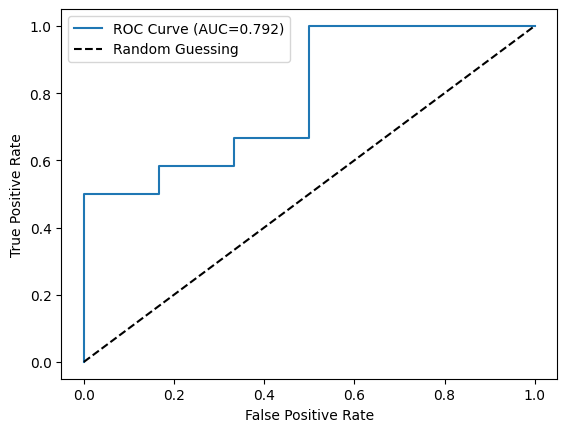

In [13]:
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, auc
import matplotlib.pyplot as plt

# Use any classification model (e.g. Logistic Regression)
model.fit(X_train_scaled, y_train)
y_probs = model.predict_proba(X_test_scaled)[:, 1]  # probability of class 1

# ROC-AUC
roc_auc = roc_auc_score(y_test, y_probs)
print(f"ROC-AUC: {roc_auc:.4f}")

# ROC Curve plot
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
plt.plot(fpr, tpr, label=f'ROC Curve (AUC={roc_auc:.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## Model Improvement

In [14]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')

print(f"Scores: {scores}")
print(f"Mean: {scores.mean():.2%}, Std: {scores.std():.2%}")

Scores: [0.7        0.66666667 0.7        0.76666667 0.63333333]
Mean: 69.33%, Std: 4.42%


## Stratified K-Fold

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Stratified K-Fold: keeps the class balance in EVERY fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. PR-AUC (or roc_auc; PR-AUC is better for imbalanced data): use the RIGHT metric
scores = cross_val_score(model, X, y, cv=skf, scoring='average_precision')  # 'average_precision' is PR-AUC in scikit-learn

print(f"PR-AUC scores: {scores}")
print(f"Mean: {scores.mean():.3f}, Std: {scores.std():.3f}")